In [1]:
pip install pandas matplotlib seaborn scipy

   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.1 MB 9.4 MB/s eta 0:00:01
   ---------------- ----------------------- 3.4/8.1 MB 8.8 MB/s eta 0:00:01
   ------------------------ --------------- 5.0/8.1 MB 8.2 MB/s eta 0:00:01
   --------------------------------- ------ 6.8/8.1 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 8.1/8.1 MB 8.0 MB/s  0:00:01
   ---------------------------------------- 0.0/38.7 MB ? eta -:--:--
   - -------------------------------------- 1.8/38.7 MB 9.1 MB/s eta 0:00:05
   --- ------------------------------------ 3.1/38.7 MB 7.7 MB/s eta 0:00:05
   ----- ---------------------------------- 5.5/38.7 MB 9.1 MB/s eta 0:00:04
   ------- -------------------------------- 7.3/38.7 MB 8.9 MB/s eta 0:00:04
   --------- ------------------------------ 9.2/38.7 MB 8.9 MB/s eta 0:00:04
   ----------- ---------------------------- 11.0/38.7 MB 8.8 MB/s eta 0:00:04
   ------------- ----

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

df = pd.read_csv('amazon_uk_products.csv')

df = df.dropna(subset=['price', 'stars', 'category'])

print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


Top 5 Most Listed Categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


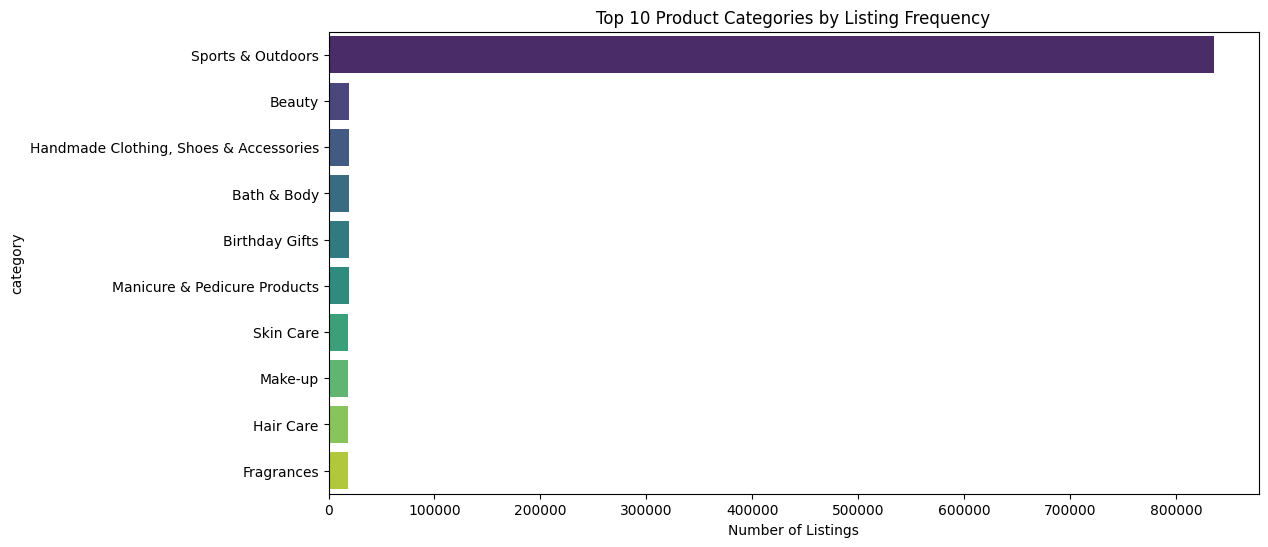

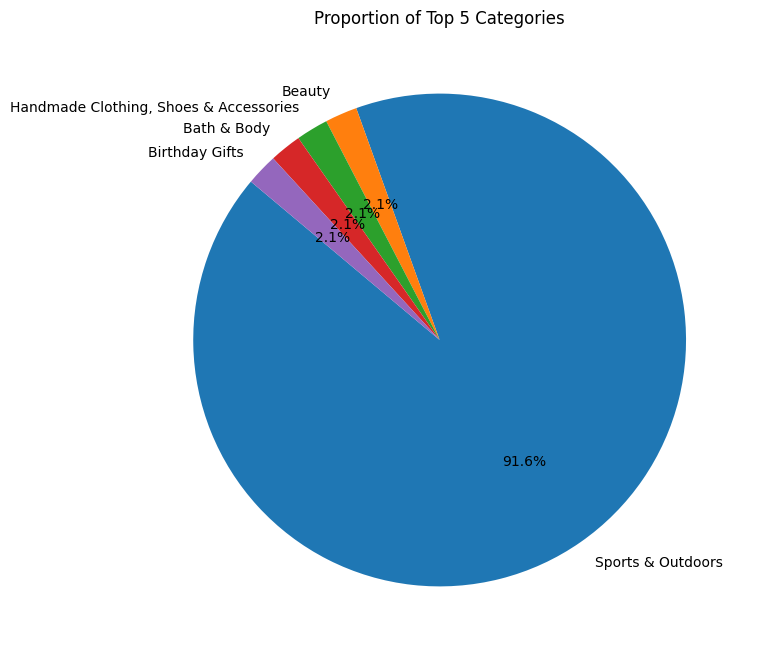

In [7]:
category_freq = df['category'].value_counts()
print("Top 5 Most Listed Categories:")
print(category_freq.head(5))

plt.figure(figsize=(12, 6))
sns.barplot(x=category_freq.head(10).values, y=category_freq.head(10).index, hue=category_freq.head(10).index, legend=False, palette='viridis')
plt.title('Top 10 Product Categories by Listing Frequency')
plt.xlabel('Number of Listings')
plt.show()

plt.figure(figsize=(8, 8))
plt.pie(category_freq.head(5), labels=category_freq.head(5).index, autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Top 5 Categories')
plt.show()

Mean: 89.24
Median: 19.09
Mode: 9.99
Std Dev: 345.61
IQR: 36.00


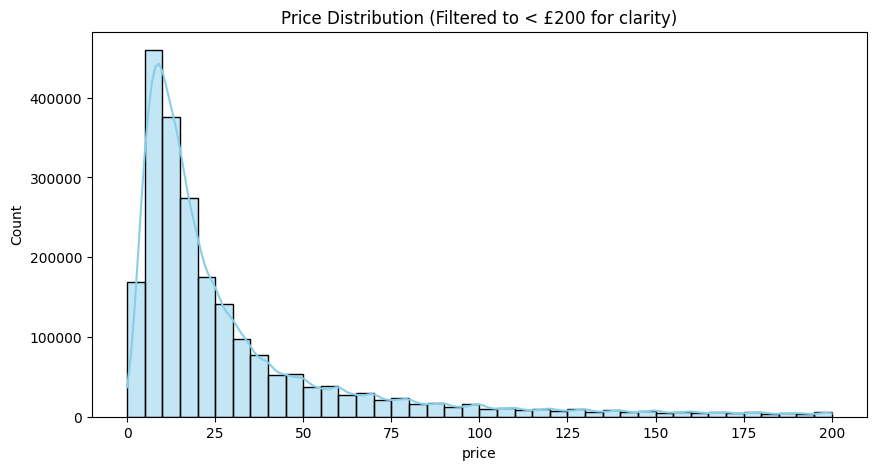

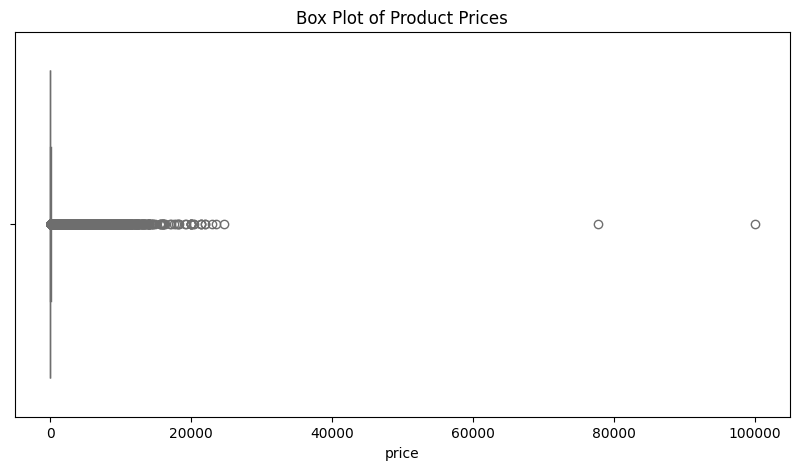

In [8]:
price_stats = {
    'Mean': df['price'].mean(),
    'Median': df['price'].median(),
    'Mode': df['price'].mode()[0],
    'Std Dev': df['price'].std(),
    'IQR': df['price'].quantile(0.75) - df['price'].quantile(0.25)
}

for stat, value in price_stats.items():
    print(f"{stat}: {value:.2f}")


plt.figure(figsize=(10, 5))
sns.histplot(df[df['price'] < 200]['price'], bins=40, kde=True, color='skyblue')
plt.title('Price Distribution (Filtered to < £200 for clarity)')
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x=df['price'], color='lightcoral')
plt.title('Box Plot of Product Prices')
plt.show()

Rating Stats: Mean=2.15, Median=0.00, Mode=0.00
Skewness: 0.08 (Negative means lean toward high ratings)
Kurtosis: -1.93


C:\Users\ASUS\AppData\Local\Temp\ipykernel_29564\3477478120.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stars', data=df, palette='magma')


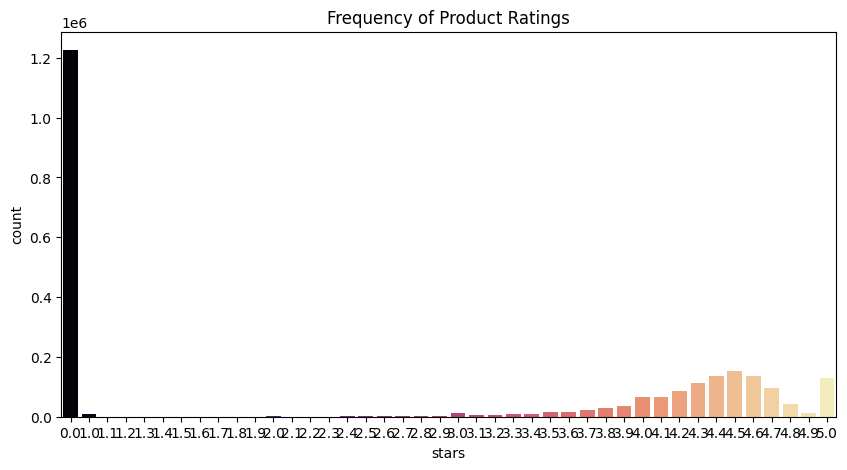

In [9]:
rating_mean = df['stars'].mean()
rating_median = df['stars'].median()
rating_mode = df['stars'].mode()[0]
rating_std = df['stars'].std()

print(f"Rating Stats: Mean={rating_mean:.2f}, Median={rating_median:.2f}, Mode={rating_mode:.2f}")

r_skew = skew(df['stars'].dropna())
r_kurt = kurtosis(df['stars'].dropna())

print(f"Skewness: {r_skew:.2f}")
print(f"Kurtosis: {r_kurt:.2f}")

plt.figure(figsize=(10, 5))
sns.countplot(x='stars', data=df, palette='magma')
plt.title('Frequency of Product Ratings')
plt.show()

In [ ]:
'''
Final Business Report Checklist:
Most Popular Category: sports and outdoors.

Price Strategy: Mean is significantly higher than the Median. This indicates a few very expensive items are pulling the average up.

Rating Patterns: No, the ratings are not normally distributed. While the skewness is low - normal distribution?-, the very low kurtosis indicates the distribution is too flat to be a bell curve.
'''